# comparaison des methodes ADAPT : shift scale

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt

from adapt_utils import run_all_methods

/Users/arnaudgrassian/Downloads/stage_recherche/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## Execution (sans et avec standardisation)

In [2]:
shift_type = "scale"

results_raw = run_all_methods(shift_type, standardize=False)
results_std = run_all_methods(shift_type, standardize=True)

results_raw["standardise"] = False
results_std["standardise"] = True
results_df = pd.concat([results_raw, results_std], ignore_index=True)
results_df

,method,intensity,mse_source,mse_target,r2_source,r2_target,standardise
0,sans adaptation,0.25,0.033010,0.032142,0.951031,0.960674,False
1,sans adaptation,0.50,0.033010,0.032376,0.951031,0.971092,False
2,sans adaptation,1.00,0.033010,0.032979,0.951031,0.982720,False
3,CORAL,0.25,0.033010,2.096946,0.951031,-1.565620,False
4,CORAL,0.50,0.033010,2.291255,0.951031,-1.045802,False
5,CORAL,1.00,0.033010,2.920155,0.951031,-0.530073,False
6,SA,0.25,0.033010,0.673269,0.951031,0.176253,False
7,SA,0.50,0.033010,0.666724,0.951031,0.404700,False
8,SA,1.00,0.033010,0.653876,0.951031,0.657389,False
9,TCA,0.25,11.091038,13.238172,-15.453007,-15.196949,False


## Comparaison (r2 cible)

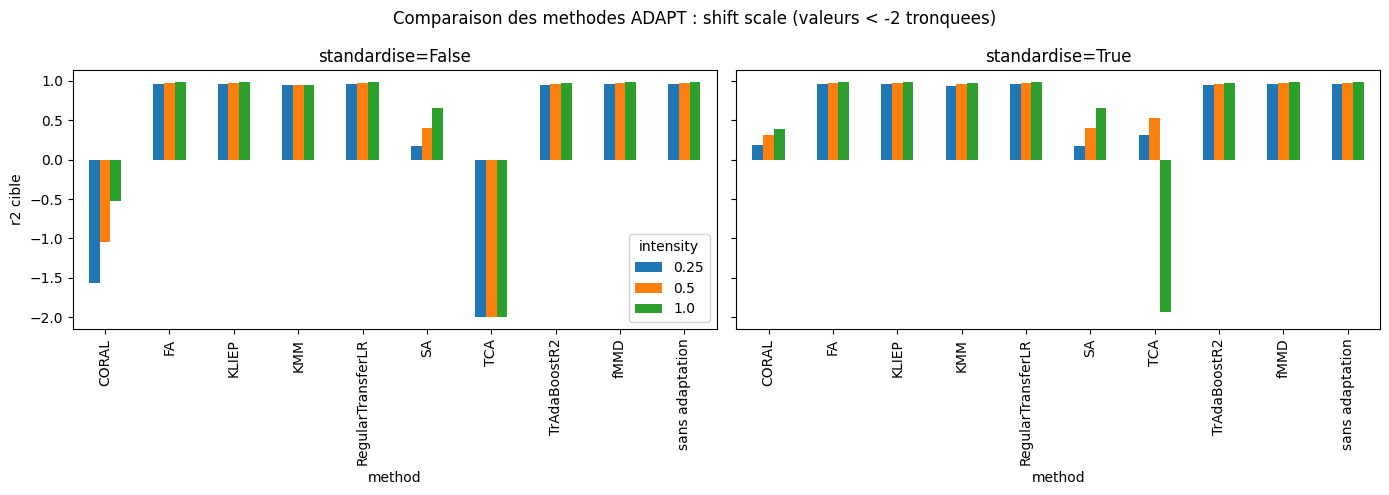

In [3]:
plot_floor = -2

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, standardise in zip(axes, [False, True]):
    subset = results_df[results_df["standardise"] == standardise]
    pivot = subset.pivot(index="method", columns="intensity", values="r2_target").clip(lower=plot_floor)
    pivot.plot(kind="bar", ax=ax, legend=(ax is axes[0]))
    ax.set_title(f"standardise={standardise}")
    ax.set_ylabel("r2 cible")

plt.suptitle(f"Comparaison des methodes ADAPT : shift {shift_type} (valeurs < {plot_floor} tronquees)")
plt.tight_layout()
plt.show()

## Source vs cible (sans standardisation)

In [4]:
subset = results_df[~results_df["standardise"]]
subset.pivot_table(index="method", columns="intensity", values=["r2_source", "r2_target"])

r2_source                      r2_target            \
intensity               0.25      0.50      1.00       0.25      0.50   
method                                                                  
CORAL               0.951031  0.951031  0.951031  -1.565620 -1.045802   
FA                  0.951023  0.951023  0.951023   0.961698  0.971976   
KLIEP               0.945831  0.945739  0.945430   0.958128  0.969117   
KMM                 0.932846  0.923313  0.908616   0.945207  0.946711   
RegularTransferLR   0.947944  0.947854  0.947724   0.961776  0.972034   
SA                  0.951031  0.951031  0.951031   0.176253  0.404700   
TCA               -15.453007 -4.325659 -4.888679 -15.196949 -3.512183   
TrAdaBoostR2        0.928386  0.928421  0.928325   0.944253  0.959060   
fMMD                0.947272  0.947272  0.947272   0.957423  0.968350   
sans adaptation     0.951031  0.951031  0.951031   0.960674  0.971092   

                             
intensity              1.00  
method                       
CORAL             -0.530073  
FA                 0.983510  
KLIEP              0.981186  
KMM                0.945611  
RegularTransferLR  0.983545  
SA                 0.657389  
TCA               -2.262445  
TrAdaBoostR2       0.975786  
fMMD               0.980564  
sans adaptation    0.982720

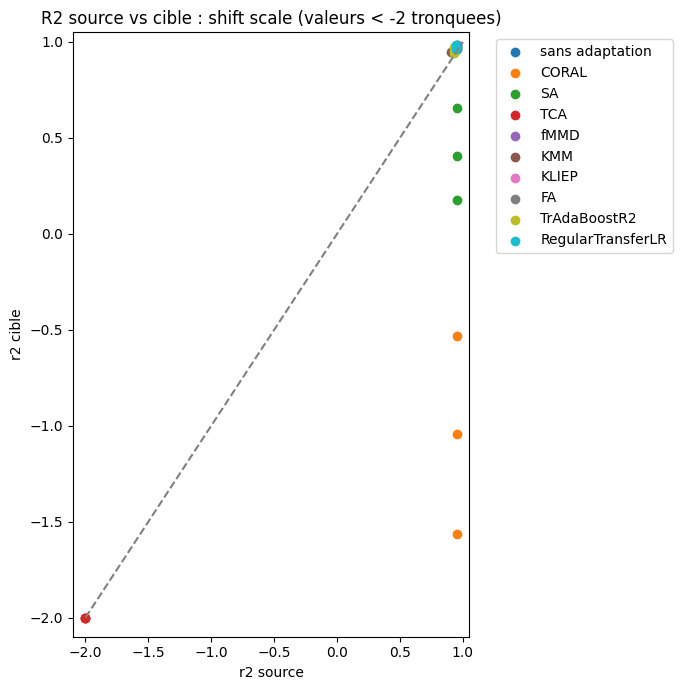

In [5]:
plot_floor = -2

fig, ax = plt.subplots(figsize=(7, 7))
for method in subset["method"].unique():
    method_data = subset[subset["method"] == method]
    x = method_data["r2_source"].clip(lower=plot_floor)
    y = method_data["r2_target"].clip(lower=plot_floor)
    ax.scatter(x, y, label=method)

ax.plot([plot_floor, 1], [plot_floor, 1], linestyle="--", color="gray")
ax.set_xlim(plot_floor - 0.1, 1.05)
ax.set_ylim(plot_floor - 0.1, 1.05)
ax.set_xlabel("r2 source")
ax.set_ylabel("r2 cible")
ax.set_title(f"R2 source vs cible : shift {shift_type} (valeurs < {plot_floor} tronquees)")
ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()